In [ ]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    GlobalAveragePooling1D,
    BatchNormalization, ReLU,
    Add, Dense, Dropout
)

from tensorflow.keras.models import Model
from tensorflow.keras.utils import to_categorical

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.layers import (
    Multiply,
    Concatenate,
    GlobalMaxPooling1D
)

from tensorflow.keras.layers import Reshape

# ============================================================
# 1. SEED
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# ============================================================
# 2. CONFIGURATION
# ============================================================

DATA_PATH = "/content/drive/MyDrive/Colab Notebooks/WISDM_ar_v1.1_raw.txt"

MODEL_PATH = "/content/best_resnet_inception.keras"

WINDOW_SIZE = 128
STRIDE = 64

N_CHANNELS = 3
N_CLASSES = 6

TIME_GAP_THRESHOLD = 200_000_000

BATCH_SIZE = 64
EPOCHS = 50

LEARNING_RATE = 0.001

class_names = [
    "WALKING",
    "JOGGING",
    "UPSTAIRS",
    "DOWNSTAIRS",
    "SITTING",
    "STANDING"
]

activity_map = {
    "Walking": 0,
    "Jogging": 1,
    "Upstairs": 2,
    "Downstairs": 3,
    "Sitting": 4,
    "Standing": 5
}


# ============================================================
# 3. LOAD WISDM DATASET
# ============================================================

def load_wisdm(path):

    columns = [
        "user",
        "activity",
        "timestamp",
        "x",
        "y",
        "z"
    ]

    df = pd.read_csv(
        path,
        header=None,
        names=columns,
        sep=",",
        engine="python",
        on_bad_lines="skip",
        skipinitialspace=True
    )

    df["z"] = (
        df["z"]
        .astype(str)
        .str.replace(";", "", regex=False)
    )

    for col in ["user", "timestamp", "x", "y", "z"]:

        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

    df["activity"] = (
        df["activity"]
        .astype(str)
        .str.strip()
    )

    df = df.dropna(
        subset=columns
    ).copy()

    df["user"] = df["user"].astype(int)

    df["timestamp"] = df["timestamp"].astype(np.int64)

    df = df[
        df["activity"].isin(activity_map.keys())
    ].copy()

    df["label"] = (
        df["activity"]
        .map(activity_map)
        .astype(int)
    )

    df = df.sort_values(
        ["user", "timestamp"]
    ).reset_index(drop=True)

    return df


df = load_wisdm(DATA_PATH)

print("Dataset shape:", df.shape)

print("Number of users:", df["user"].nunique())

print("\nActivity distribution:")

print(df["activity"].value_counts())



# ============================================================
# 4. TIMESTAMP CHECK
# ============================================================

timestamp_diff = (
    df.groupby("user")["timestamp"].diff()
)

print("\nTimestamp statistics:")

print(timestamp_diff.describe())


# ============================================================
# 5. SUBJECT-WISE SPLIT
# ============================================================

users = np.sort(df["user"].unique())

rng = np.random.RandomState(SEED)

rng.shuffle(users)

n_users = len(users)

n_train = int(n_users * 0.70)

n_val = int(n_users * 0.15)

train_users = users[:n_train]

val_users = users[
    n_train:n_train + n_val
]

test_users = users[
    n_train + n_val:
]

print("\nTrain users:", train_users)

print("Validation users:", val_users)

print("Test users:", test_users)


assert len(set(train_users) & set(val_users)) == 0

assert len(set(train_users) & set(test_users)) == 0

assert len(set(val_users) & set(test_users)) == 0


# ============================================================
# 6. SPLIT DATASET
# ============================================================

train_df = df[
    df["user"].isin(train_users)
].copy()

val_df = df[
    df["user"].isin(val_users)
].copy()

test_df = df[
    df["user"].isin(test_users)
].copy()


for name, split_df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:

    print(f"\n{name} activity distribution:")

    print(split_df["activity"].value_counts())

Dataset shape: (1086465, 7)
Number of users: 36

Activity distribution:
activity
Walking       418393
Jogging       336445
Upstairs      122869
Downstairs    100425
Sitting        59939
Standing       48394
Name: count, dtype: int64

Timestamp statistics:
count    1.086429e+06
mean     7.734891e+08
std      2.251700e+11
min      0.000000e+00
25%      4.962200e+07
50%      4.998800e+07
75%      5.004900e+07
max      1.296121e+14
Name: timestamp, dtype: float64

Train users: [36 14 27 31 17 32 22 13  9 18 10 35  1  5 30 16 20  6 12  2 25  3 34  4
 33]
Validation users: [24 28 11 23 19]
Test users: [26  7 21  8 15 29]

TRAIN activity distribution:
activity
Walking       289825
Jogging       222343
Upstairs       80067
Downstairs     67705
Sitting        47559
Standing       34323
Name: count, dtype: int64

VALIDATION activity distribution:
activity
Walking       56774
Jogging       53242
Upstairs      19439
Downstairs    13153
Standing       3976
Sitting        3224
Name: count, dtype: in

In [ ]:
# ============================================================
# 7. SLIDING WINDOW GENERATION
# ============================================================

def create_windows(
    data,
    window_size=128,
    stride=64
):

    X = []
    y = []
    window_users = []

    for user, user_df in data.groupby("user"):

        user_df = user_df.sort_values(
            "timestamp"
        ).reset_index(drop=True)

        values = user_df[
            ["x", "y", "z"]
        ].to_numpy(dtype=np.float32)

        labels = user_df[
            "label"
        ].to_numpy(dtype=np.int32)

        timestamps = user_df[
            "timestamp"
        ].to_numpy(dtype=np.int64)

        # Activity boundary
        activity_change = (
            labels[1:] != labels[:-1]
        )

        # Timestamp boundary
        timestamp_diff = np.diff(timestamps)

        time_gap = (
            timestamp_diff > TIME_GAP_THRESHOLD
        )

        # Combine boundaries
        boundaries = np.where(
            activity_change | time_gap
        )[0] + 1

        starts = np.concatenate([
            [0],
            boundaries
        ])

        ends = np.concatenate([
            boundaries,
            [len(values)]
        ])

        # Generate windows
        for start, end in zip(starts, ends):

            segment_x = values[start:end]

            segment_y = labels[start:end]

            if len(segment_x) < window_size:
                continue

            for i in range(
                0,
                len(segment_x) - window_size + 1,
                stride
            ):

                window_x = segment_x[
                    i:i + window_size
                ]

                window_y = segment_y[
                    i:i + window_size
                ]

                label = window_y[0]

                X.append(window_x)

                y.append(label)

                window_users.append(user)

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.int32),
        np.asarray(window_users)
    )


# ============================================================
# 8. GENERATE WINDOWS
# ============================================================

X_train, y_train, train_window_users = create_windows(
    train_df,
    WINDOW_SIZE,
    STRIDE
)

X_val, y_val, val_window_users = create_windows(
    val_df,
    WINDOW_SIZE,
    STRIDE
)

X_test, y_test, test_window_users = create_windows(
    test_df,
    WINDOW_SIZE,
    STRIDE
)


print("\nWindow Shapes")

print("X_train:", X_train.shape)

print("X_val:", X_val.shape)

print("X_test:", X_test.shape)


if min(
    len(X_train),
    len(X_val),
    len(X_test)
) == 0:

    raise ValueError(
        "Empty window dataset. Check data and timestamp units."
    )


# ============================================================
# 9. CLASS DISTRIBUTION
# ============================================================

for name, labels in [
    ("TRAIN", y_train),
    ("VALIDATION", y_val),
    ("TEST", y_test)
]:

    print(f"\n{name} window distribution:")

    counts = np.bincount(
        labels,
        minlength=N_CLASSES
    )

    for i, activity in enumerate(class_names):

        print(
            f"{activity}: {counts[i]}"
        )


# Check all classes in training data

classes = np.unique(y_train)

if len(classes) != N_CLASSES:

    raise ValueError(
        "Some activity classes are missing from training data."
    )


# ============================================================
# 10. NORMALIZATION
# ============================================================

mean = X_train.mean(
    axis=(0, 1),
    keepdims=True
)

std = X_train.std(
    axis=(0, 1),
    keepdims=True
)

std = np.maximum(
    std,
    1e-8
)

X_train = (X_train - mean) / std

X_val = (X_val - mean) / std

X_test = (X_test - mean) / std


print("\nNormalization completed.")

print("Mean:", mean.reshape(-1))

print("Std:", std.reshape(-1))


# ============================================================
# 11. ONE-HOT ENCODING
# ============================================================

y_train_onehot = to_categorical(
    y_train,
    num_classes=N_CLASSES
)

y_val_onehot = to_categorical(
    y_val,
    num_classes=N_CLASSES
)

y_test_onehot = to_categorical(
    y_test,
    num_classes=N_CLASSES
)


# ============================================================
# 12. CLASS WEIGHTS
# ============================================================

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(N_CLASSES),
    y=y_train
)

class_weights = dict(
    enumerate(weights)
)

print("\nClass weights:")

print(class_weights)


Window Shapes
X_train: (9747, 128, 3)
X_val: (2247, 128, 3)
X_test: (2401, 128, 3)

TRAIN window distribution:
WALKING: 4295
JOGGING: 2275
UPSTAIRS: 1065
DOWNSTAIRS: 893
SITTING: 708
STANDING: 511

VALIDATION window distribution:
WALKING: 870
JOGGING: 818
UPSTAIRS: 279
DOWNSTAIRS: 177
SITTING: 45
STANDING: 58

TEST window distribution:
WALKING: 1032
JOGGING: 558
UPSTAIRS: 303
DOWNSTAIRS: 223
SITTING: 133
STANDING: 152

Normalization completed.
Mean: [0.65133816 7.643836   0.5670966 ]
Std: [6.217348  6.126874  4.6443944]

Class weights:
{0: np.float64(0.3782305005820722), 1: np.float64(0.7140659340659341), 2: np.float64(1.5253521126760563), 3: np.float64(1.8191489361702127), 4: np.float64(2.294491525423729), 5: np.float64(3.179060665362035)}


In [ ]:
# ============================================================
# 13. RESNET RESIDUAL BLOCK
# ============================================================

def residual_block(x, filters, kernel_size=3, dropout_rate=0.2):

    shortcut = x

    x = Conv1D(
        filters,
        kernel_size,
        padding="same",
        use_bias=False,
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(x)

    x = BatchNormalization()(x)
    x = ReLU()(x)

    x = Dropout(dropout_rate)(x)

    x = Conv1D(
        filters,
        kernel_size,
        padding="same",
        use_bias=False,
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(x)

    x = BatchNormalization()(x)

    if shortcut.shape[-1] != filters:

        shortcut = Conv1D(
            filters,
            1,
            padding="same",
            use_bias=False
        )(shortcut)

        shortcut = BatchNormalization()(shortcut)

    x = Add()([x, shortcut])

    x = ReLU()(x)

    return x


# ============================================================
# 14. INCEPTION RESIDUAL BLOCK
# ============================================================

def inception_residual_block(
    x,
    filters,
    dropout_rate=0.2
):

    shortcut = x

    # Branch 1: Kernel Size 3

    branch1 = Conv1D(
        filters // 3,
        3,
        padding="same",
        activation="relu"
    )(x)

    # Branch 2: Kernel Size 5

    branch2 = Conv1D(
        filters // 3,
        5,
        padding="same",
        activation="relu"
    )(x)

    # Branch 3: Kernel Size 7

    branch3 = Conv1D(
        filters // 3,
        7,
        padding="same",
        activation="relu"
    )(x)

    # Concatenate Multi-scale Features

    x = Concatenate()([
        branch1,
        branch2,
        branch3
    ])

    # Feature Fusion

    x = Conv1D(
        filters,
        1,
        padding="same",
        use_bias=False,
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(x)

    x = BatchNormalization()(x)

    # Shortcut Projection

    if shortcut.shape[-1] != filters:

        shortcut = Conv1D(
            filters,
            1,
            padding="same",
            use_bias=False
        )(shortcut)

        shortcut = BatchNormalization()(shortcut)

    # Residual Connection

    x = Add()([x, shortcut])

    x = ReLU()(x)

    x = Dropout(dropout_rate)(x)

    return x


# ============================================================
# 15. BUILD RESNET + INCEPTION MODEL
# ============================================================

def build_resnet_inception():

    inputs = Input(
        shape=(WINDOW_SIZE, N_CHANNELS)
    )

    # --------------------------------
    # Initial Convolution
    # --------------------------------

    x = Conv1D(
        32,
        5,
        padding="same",
        use_bias=False,
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(inputs)

    x = BatchNormalization()(x)

    x = ReLU()(x)

    # --------------------------------
    # ResNet Block
    # --------------------------------

    x = residual_block(
        x,
        32,
        dropout_rate=0.2
    )

    x = MaxPooling1D(2)(x)

    # --------------------------------
    # Inception Residual Block
    # --------------------------------

    x = inception_residual_block(
        x,
        64,
        dropout_rate=0.2
    )

    # --------------------------------
    # Global Feature Extraction
    # --------------------------------

    x = GlobalAveragePooling1D()(x)

    # --------------------------------
    # Fully Connected Layer
    # --------------------------------

    x = Dense(
        64,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(x)

    x = Dropout(0.5)(x)

    # --------------------------------
    # Output Layer
    # --------------------------------

    outputs = Dense(
        N_CLASSES,
        activation="softmax"
    )(x)

    model = Model(
        inputs,
        outputs,
        name="WISDM_ResNet_Inception"
    )

    return model


# ============================================================
# 16. COMPILE MODEL
# ============================================================

MODEL_PATH = "/content/best_resnet_inception.keras"

model = build_resnet_inception()

model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),

    loss="categorical_crossentropy",

    metrics=["accuracy"]
)

model.summary()


# ============================================================
# 17. CALLBACKS
# ============================================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)


# ============================================================
# 18. MODEL TRAINING
# ============================================================

history = model.fit(

    X_train,

    y_train_onehot,

    validation_data=(
        X_val,
        y_val_onehot
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    shuffle=True,

    class_weight=class_weights,

    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ],

    verbose=1
)

Model: "WISDM_ResNet_Inception"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 3)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 128, 32)   │        480 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 32)   │        128 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 128, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 128, 32)   │      3,072 │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 32)   │        128 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 128, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128, 32)   │          0 │ re_lu_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 128, 32)   │      3,072 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 32)   │        128 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128, 32)   │          0 │ batch_normalizat… │
│                     │                   │            │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 128, 32)   │          0 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 64, 32)    │          0 │ re_lu_2[0][0]     │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 64, 21)    │      2,037 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 64, 21)    │      3,381 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 64, 21)    │      4,725 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 63)    │          0 │ conv1d_3[0][0],   │
│ (Concatenate)       │                   │            │ conv1d_4[0][0],   │
│                     │                   │            │ conv1d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 64, 64)    │      4,032 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 64, 64)    │      2,048 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64)    │        256 │ conv1d_6[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 28,293 (110.52 KB)

 Trainable params: 27,845 (108.77 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/50
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.3625 - loss: 1.5547
Epoch 1: val_loss improved from None to 1.33867, saving model to /content/best_resnet_inception.keras

Epoch 1: finished saving model to /content/best_resnet_inception.keras
153/153 ━━━━━━━━━━━━━━━━━━━━ 39s 124ms/step - accuracy: 0.4913 - loss: 1.2621 - val_accuracy: 0.4846 - val_loss: 1.3387 - learning_rate: 3.0000e-04
Epoch 2/50
147/153 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6543 - loss: 0.8540
Epoch 2: val_loss improved from 1.33867 to 0.94542, saving model to /content/best_resnet_inception.keras

Epoch 2: finished saving model to /content/best_resnet_inception.keras
153/153 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.6868 - loss: 0.7957 - val_accuracy: 0.6769 - val_loss: 0.9454 - learning_rate: 3.0000e-04
Epoch 3/50
148/153 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7535 - loss: 0.6378
Epoch 3: val_loss improved from 0.94542 to 0.72759, saving model to /content/best_resnet_inceptio

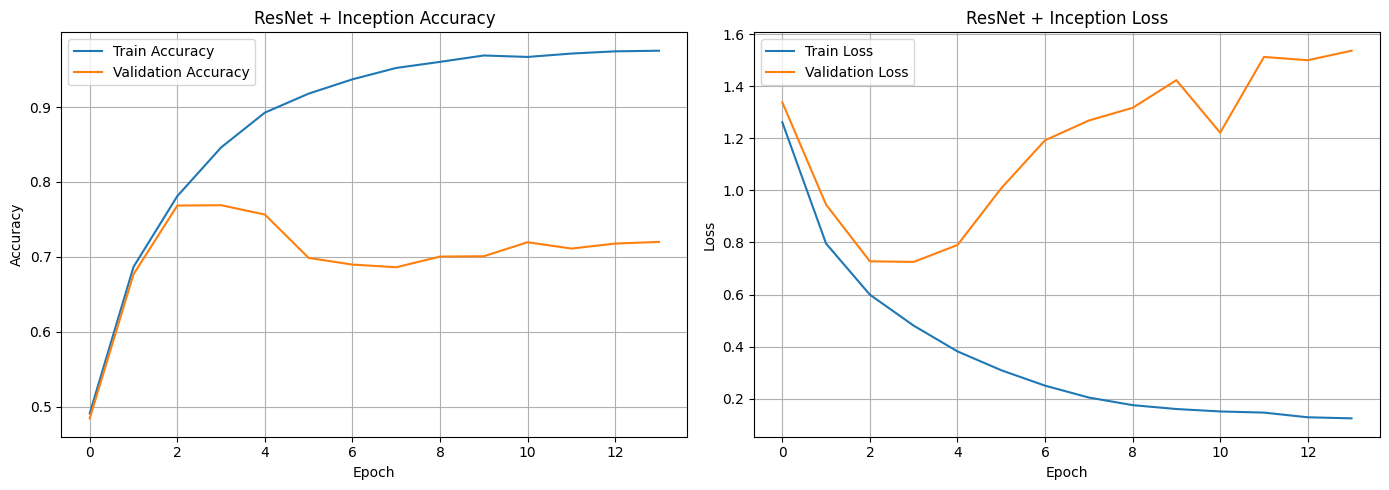


RESNET + INCEPTION TEST RESULTS
Accuracy  : 0.9067
Precision : 0.8779
Recall    : 0.8975
Macro F1  : 0.8862

Classification Report
              precision    recall  f1-score   support

     WALKING     0.9863    0.9099    0.9466      1032
     JOGGING     0.9946    0.9946    0.9946       558
    UPSTAIRS     0.7199    0.8482    0.7788       303
  DOWNSTAIRS     0.5663    0.6323    0.5975       223
     SITTING     1.0000    1.0000    1.0000       133
    STANDING     1.0000    1.0000    1.0000       152

    accuracy                         0.9067      2401
   macro avg     0.8779    0.8975    0.8862      2401
weighted avg     0.9172    0.9067    0.9105      2401



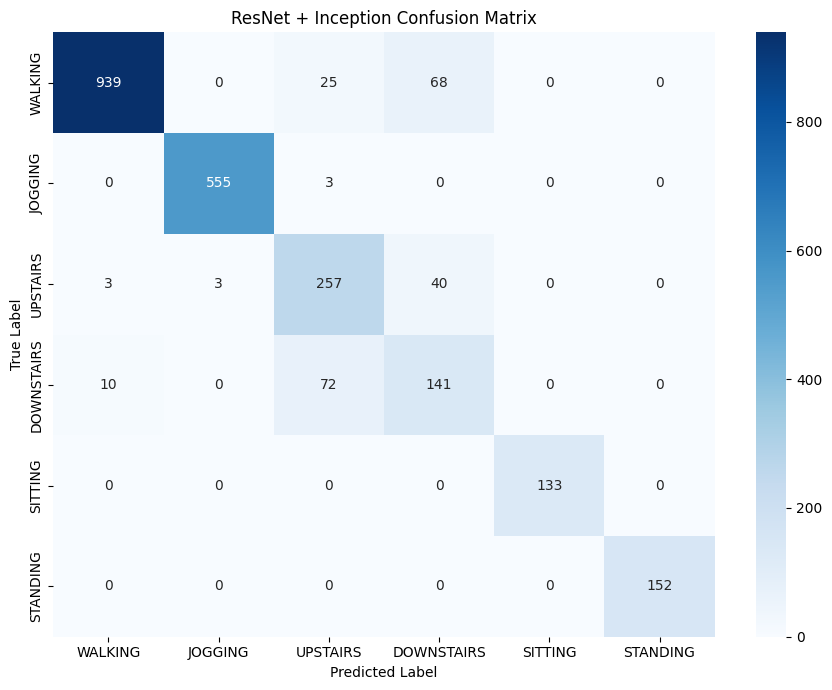

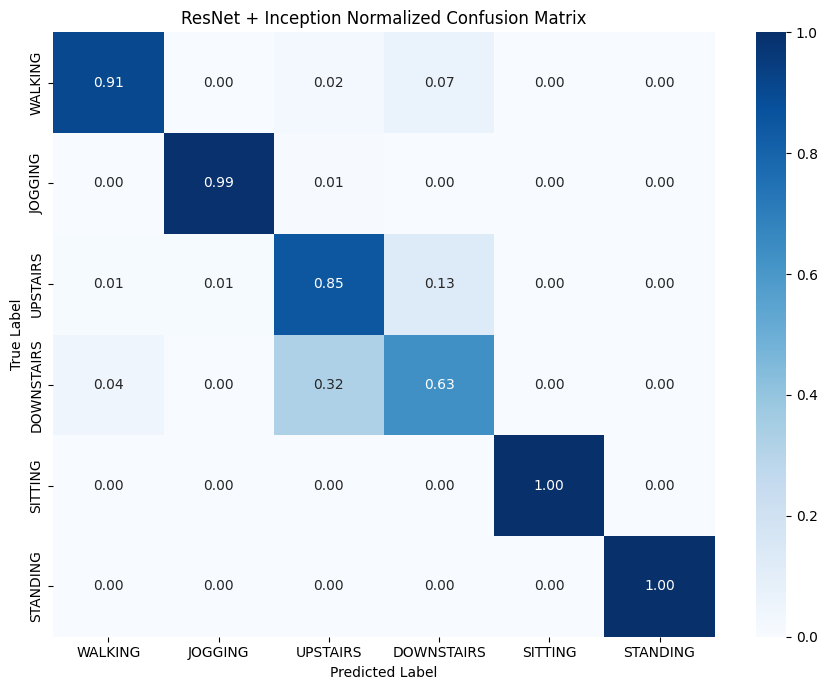


Final Results
             Model  Accuracy  Precision   Recall  Macro F1
ResNet + Inception  0.906706   0.877854 0.897497   0.88624


In [ ]:
# ============================================================
# 20. TRAINING HISTORY
# ============================================================

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="Train Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("ResNet + Inception Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)


plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="Train Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("ResNet + Inception Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 21. LOAD BEST MODEL
# ============================================================

model = tf.keras.models.load_model(
    MODEL_PATH
)


# ============================================================
# 22. TEST PREDICTION
# ============================================================

y_prob = model.predict(
    X_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

y_pred = np.argmax(
    y_prob,
    axis=1
)


# ============================================================
# 23. EVALUATION METRICS
# ============================================================

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)


print("\n================================")

print("RESNET + INCEPTION TEST RESULTS")

print("================================")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"Macro F1  : {f1:.4f}")


# ============================================================
# 24. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report")

print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(N_CLASSES),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 25. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(N_CLASSES)
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("ResNet + Inception Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()


# Normalized Confusion Matrix

cm_normalized = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(N_CLASSES),
    normalize="true"
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1
)

plt.title("ResNet + Inception Normalized Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()


# ============================================================
# 26. SAVE RESULTS
# ============================================================

results = {
    "Model": "ResNet + Inception",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "Macro F1": f1
}

results_df = pd.DataFrame([results])

print("\nFinal Results")

print(
    results_df.to_string(index=False)
)
